# 14d — Tumour growth, oxygen and necrosis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/14d_coupled_tumour_growth.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

The slide demonstrations move from Fisher–KPP growth on normal BrainWeb anatomy
to a coupled model of viable tumour, oxygen and necrotic material. Here you can
reproduce that progression, change the seed and biological parameters, and view
all four fields at the same time and anatomical location.

The full numerical solver used by the slides is included at a recorded source
version, alongside the existing BrainWeb data. The histological illustration is
a visual guide to the biological questions. The simulated fields represent a
small selection of its processes.

### Learning goals

1. Explain the feedback between viable tumour, oxygen availability and necrosis.
2. Compare a coupled model with a reference sharing its seed, anatomy and transport parameters.
3. Separate numerical verification, assumed mechanisms and biological validation.
4. Reproduce a recorded preset and save its parameters, plots and animation.

## Concepts and two reading paths

Choose an explanation first, then use the paired exercises to compare what each route establishes. Both routes use the same setup and numerical experiment; run the shared code cells in order.

<details open><summary><strong>For biomedical and imaging readers</strong></summary>

**Starting question.** How could reduced oxygen supply and increased consumption alter the pattern of viable tumour and dead material?

Begin with the histological picture: identify an invasion border, vessels and necrotic regions. Tell a causal story in ordinary language. Growing tumour can increase demand; reduced delivery can limit oxygen availability; low oxygen can slow proliferation and promote cell death. The model represents selected links in that story. Its necrotic material remains in place and occupies growth capacity.

Compare the viable tumour, oxygen and necrotic panels with the matched reference. Predict where oxygen might fall first and why fewer viable cells need not mean an equally large accumulation of necrosis. BrainWeb is normal anatomy; simulated fields are distinct from observed enhancement, FLAIR abnormalities or measured oxygen.

**Result.** Explain the spatial feedback and its possible imaging interpretation while distinguishing represented mechanisms from omitted vessels, immune processes and phenotype switching.

</details>

<details><summary><strong>For computational readers</strong></summary>

**Starting question.** Which coupled equations imply the total-material balance and the Fisher–KPP limit?

On no-flux domain $\Omega$, $c(\mathbf x,t)$ and $z(\mathbf x,t)$ are viable cells and necrotic equivalents per mm³; $o(\mathbf x,t)$ is relative oxygen:
$$\partial_tc=\nabla\cdot(D\nabla c)+\rho g(o)c[1-(c+z)/K]_+-\delta h(o)c,$$
$$\partial_tz=\delta h(o)c-\lambda_z z,\qquad
0=\ell_o^2\nabla^2o+p(1-o)-\beta(c/K)o.$$
Here $p=[1+\alpha(c+z)/K]^{-1}$, $g(o)=\min(1,o/\theta_p)$ and $h(o)=[1-o/\theta_d]_+$, with $0<\theta_d<\theta_p<1$ and $[a]_+=\max(a,0)$.

Adding and integrating gives
$$\frac{d}{dt}\int_\Omega(c+z)dV
=\int_\Omega\rho g(o)c[1-(c+z)/K]_+dV-\lambda_z\int_\Omega z\,dV.$$
Death transfer cancels. With $\beta=0$, positive delivery, $z_0=0$, constant $K$ and $0\le c_0\le K$, the oxygen solution is $o=1$, necrosis remains zero and the matched system recovers Fisher–KPP. Compare identical initialization, boundaries, grid, transport, proliferation rate and carrying capacity.

**Result.** Establish a balance law and its limiting-case assumptions; use the units table below to check every term.

</details>

**Route through this notebook.** Read the biological picture, anatomical comparison and overlays for the biomedical route; work through equations/units, the limiting case and the balance above for the computational route.

## Run in Colab or locally

In Colab, connect to a **CPU** runtime and choose **Runtime → Run all**. Setup
downloads this repository's shared code and data, installs the numerical
dependencies, and enables widgets. The presentation and companion repositories
are not downloaded. No GPU, API key, patient data or Drive mount is required.

Locally, use `uv sync --locked --extra dev`, then run this notebook with the
project kernel. The first simulation includes JIT compilation. The default
4-mm, 90-day run is smaller than the slide presets. The 2-mm comparison costs
more CPU time and memory; native 1-mm histories can use several GB.

Save a Colab copy in Drive to retain edits. Download exports before the temporary
runtime ends. GitHub displays the saved illustration and reference plots;
interactive controls require a running kernel.

In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8", "ipywidgets>=8.1", "nibabel>=5.3,<6", "scipy>=1.14,<2", "numba>=0.61,<1", "imageio-ffmpeg>=0.6,<1"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

from dataclasses import replace
from IPython.display import Image, display
from brainsmodels import growth_coupled as lesson
OUTPUT = root / ".build/growth-14d"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 95, "font.size": 10})
print("Solver source:", lesson.SOURCE_COMMIT)
print("Anatomy and histological illustration are bundled; no companion checkout is needed.")

Matplotlib is building the font cache; this may take a moment.


Checkout: /private/var/folders/1g/_4x26lps6mgg1tr73d7g2bmh0000gp/T/brainsmodels-notebooks-w2y8rvc5/project
Python: 3.12.14 | NumPy: 2.5.2


Solver source: 81ecd42e6f37692a711208caa8d24361904f7e65
Anatomy and histological illustration are bundled; no companion checkout is needed.


## 1. Start with the biological picture

Identify the invasion border, necrotic areas, vascular structures and different
cell types. Before running a model, predict which of these features could be
represented by one density field, and which require additional variables.

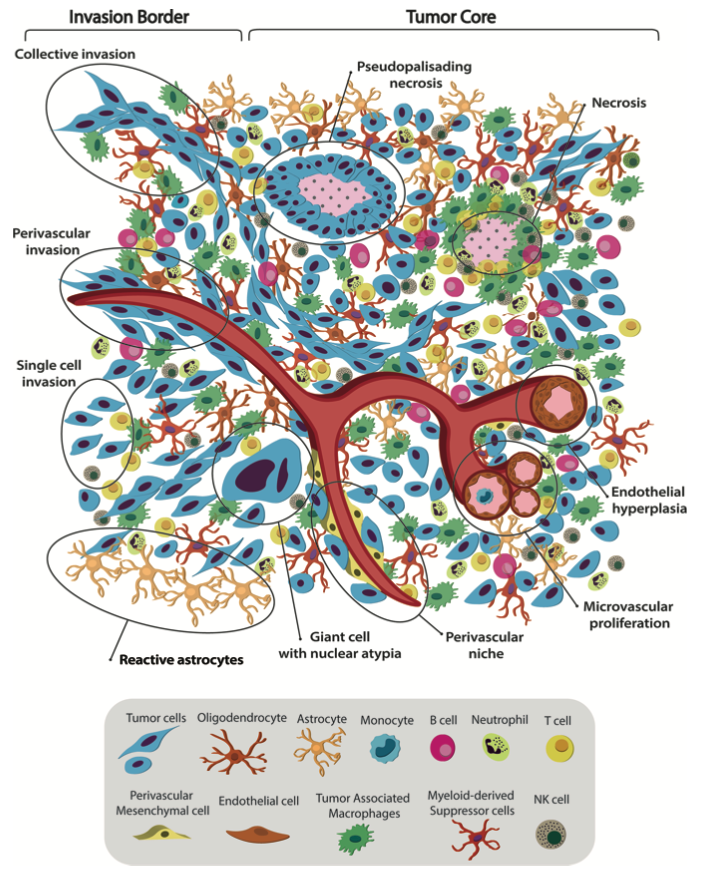

In [2]:
display(Image(filename=str(lesson.ASSETS / "comba2021_figure1.png"), width=650))

**Illustration:** Figure 1 from Comba et al. (2021), *Uncovering
Spatiotemporal Heterogeneity of High-Grade Gliomas*, Frontiers in Oncology
11:703764, [doi:10.3389/fonc.2021.703764](https://doi.org/10.3389/fonc.2021.703764).
© 2021 Comba and coauthors, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
The diagram and legend are reproduced from the slide's embedded image.

| Visual clue | Representation in this lesson |
|---|---|
| Invasion border | Effective population dispersal through an assigned tissue coefficient |
| Reduced oxygen and necrosis | Relative oxygen field and viable-to-necrotic transfer |
| Vascular structures | A stipulated perfusion rule; vessels and angiogenesis are not resolved |
| Immune cells, reactive astrocytes, perivascular niches and collective invasion | Additional biology to discuss; no explicit state variables here |

Neither model explicitly implements go-or-grow phenotype switching. A necrotic
field alone also does not establish that pseudopalisading structures have been
reproduced.

## 2. Write the equations and units

The reference is Fisher–KPP:

$$\partial_t c=\nabla\cdot(D\nabla c)+\rho c(1-c/K).$$

The coupled model uses viable density $c$, necrotic material $z$ and oxygen $o$:

$$\partial_t c=\nabla\cdot(D\nabla c)+\rho g(o)c[1-(c+z)/K]_+-\delta h(o)c,$$
$$\partial_t z=\delta h(o)c-\lambda_z z,$$
$$0=\ell_o^2\nabla^2o+p(1-o)-\beta(c/K)o,
\qquad p=\frac{1}{1+\alpha(c+z)/K}.$$

Here $[a]_+=\max(a,0)$, $g(o)=\min(1,o/\theta_p)$ and
$h(o)=[1-o/\theta_d]_+$, with $0<\theta_d<\theta_p<1$.

| Quantity | Meaning and units | Coupled slide value |
|---|---|---|
| $c,z,K$ | Viable cells, necrotic equivalents and capacity, per mm³ | $K=100000$ |
| $D_{WM},D_{GM}$ | Assigned scalar dispersal coefficients, mm²/day | 0.5, 0.1 |
| $\rho$ | Proliferation rate, day⁻¹ | 0.04 |
| $o,p$ | Relative oxygen and relative delivery, dimensionless | Computed |
| $\ell_o$ | Oxygen smoothing length, mm | 0.2 |
| $\beta,\alpha$ | Uptake and perfusion suppression, dimensionless | 4, 4 |
| $\theta_p,\theta_d$ | Oxygen proliferation/death thresholds | 0.3, 0.1 |
| $\delta,\lambda_z$ | Death-transfer and clearance rates, day⁻¹ | 0.5, 0 |

Grey matter, white matter and the glial class form the growth domain. CSF and
other classes are closed barriers; cells and oxygen have zero normal boundary
flux. Necrotic material is immobile and consumes no oxygen. $K$ limits births,
rather than imposing a hard packing constraint on incoming diffusion.

The two runs share initialization, grid, coefficients and transport domain.
Their reaction equations differ. All rates and thresholds are assigned teaching
values. At 2–4 mm, the 0.2-mm oxygen length and capillary structures remain
unresolved. No treatment, mass effect, fibre anisotropy or vascular dynamics is
included.

**Shared implementation details.** Conservative harmonic face fluxes prevent
periodic wrapping and transport across closed barriers. A positivity bound
controls the diffusion step; frozen-oxygen reaction substeps are composed to
first order in time. A preconditioned conjugate-gradient solve updates oxygen
and rejects non-convergence. The pinned numerical source is unchanged. Integer
anatomical sampling preserves labels at sampled locations but can remove thin
barriers; changing spacing changes geometry as well as numerical resolution.

## 3. Check a limiting case before interpreting the anatomy

**Biomedical prediction.** With uptake disabled and no initial necrotic material,
oxygen should remain available, births should no longer be oxygen-limited and
no death transfer should occur. Predict the four panels before running.

**Computational argument.** Set $\beta=0$ and write $w=o-1$. With $\ell_o>0$,
positive perfusion $p$ and no-flux boundaries, multiplication by $w$ and
integration give
$$0=-\ell_o^2\int_\Omega|\nabla w|^2dV-\int_\Omega p w^2dV.$$
Both terms are nonpositive, so $o=1$. Since $\theta_d<\theta_p<1$, $g=1$ and
$h=0$. If $z_0=0$, then $z=0$ for all time. For constant $K$ and
$0\le c_0\le K$, nonnegative dispersal with no flux preserves the Fisher–KPP
range $0\le c\le K$, so the clipped birth term equals the reference logistic
term. Initial density above $K$ would break this last equivalence.

**Shared check.** Use the same seed, anatomy, grid, boundaries, $D$, $\rho$ and
$K$. The numerical comparison below tests agreement up to solver tolerance;
the continuum argument alone does not guarantee identical finite-step errors.
This checks implementation consistency. Testing the oxygen closure biologically
would require independent measurements.

In [3]:
brain_small = lesson.Brain(np.ones((9, 7, 5), np.float32),
    np.full((9, 7, 5), 3, np.uint8), np.eye(4), 1.)
p = replace(lesson.preset()[1], origin_mm=(4., 3., 2.), radii_mm=(2.,)*3,
            initial_density=20000., duration_days=2., frame_days=1., dt_days=.1,
            oxygen_uptake_ratio=0.)
limit = lesson.simulate(brain_small, p, compare=True)
np.testing.assert_allclose(limit.final_density, limit.comparison.final_density, rtol=3e-6)
np.testing.assert_array_equal(limit.final_necrosis, 0.)
np.testing.assert_allclose(limit.final_oxygen, 1., atol=1e-6)
print("PASS: zero uptake recovers the reference; oxygen remains normal; no necrosis.")

PASS: zero uptake recovers the reference; oxygen remains normal; no necrosis.


## 4. Compute a small anatomical comparison

The teaching preset uses a Gaussian seed centred at RAS+ $(-30,25,30)$ mm,
standard deviations $(6,6,6)$ mm, peak 80000 cells/mm³ and initial $z=0$.
The Gaussian is truncated at three standard deviations and restricted to the
growth domain. It uses 4-mm sampling, a maximum 0.5-day internal step and saved
states every 6 days through day 90. The controls below can switch to the slide
presets or original Fisher–KPP model.

**Predict:** Where should oxygen fall first? Will a viable-cell deficit relative
to Fisher–KPP necessarily equal the necrotic-cell count? Consider inhibited
births as well as death transfer.

{
  "parameters": {
    "origin_mm": [
      -30,
      25,
      30
    ],
    "radii_mm": [
      6,
      6,
      6
    ],
    "seed_profile": "gaussian",
    "initial_density": 80000,
    "d_white": 0.5,
    "d_gray": 0.1,
    "d_csf": 0,
    "spatial_multiplier": 1.0,
    "spatial_width_mm": 30.0,
    "rho": 0.04,
    "carrying_capacity": 100000,
    "duration_days": 90,
    "dt_days": 0.5,
    "frame_days": 6.0,
    "auto_substep": true,
    "model": "coupled",
    "oxygen_length_mm": 0.2,
    "oxygen_uptake_ratio": 4,
    "perfusion_suppression": 4,
    "oxygen_prolif_level": 0.3,
    "oxygen_death_level": 0.1,
    "necrosis_rate": 0.5,
    "necrosis_clearance": 0,
    "oxygen_rtol": 1e-07,
    "oxygen_maxiter": 200
  },
  "numerical_record": {
    "spacing_mm": 4.0,
    "shape": [
      46,
      55,
      46
    ],
    "safe_dt_days": 4.8,
    "actual_max_dt_days": 0.5,
    "internal_steps": 180,
    "elapsed_seconds": 0.32635279100031767,
    "model": "coupled",
    "coeffic

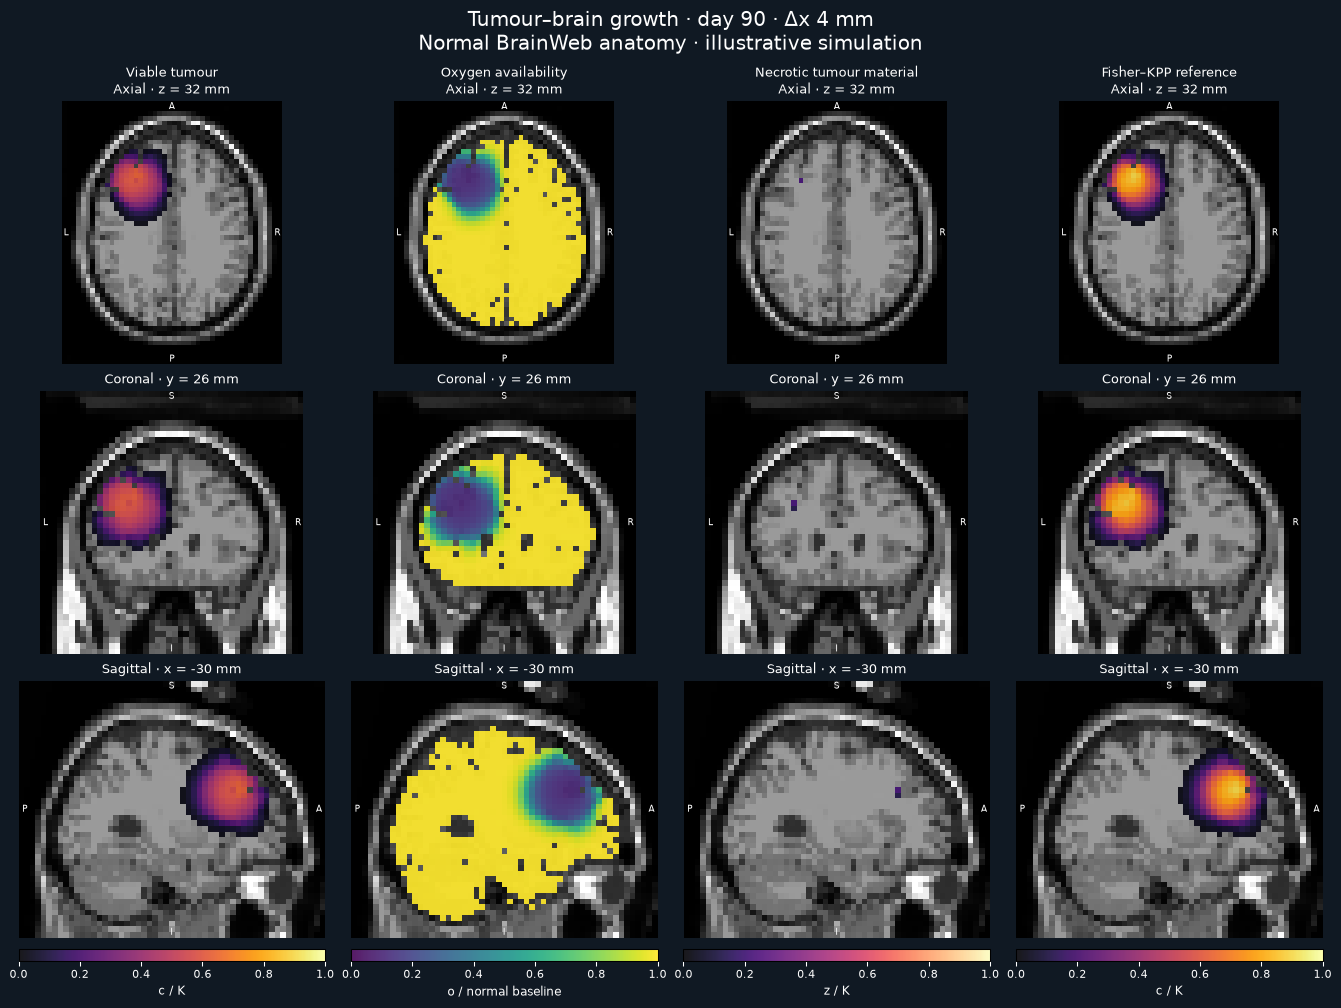

In [4]:
spacing, parameters = lesson.preset("teaching")
brain, result = lesson.run_comparison(parameters, spacing=spacing)
print(json.dumps({"parameters": result.parameters, "numerical_record": result.metadata}, indent=2))
figure = lesson.plot_comparison(brain, result)
figure.savefig(OUTPUT / "comparison.png", dpi=120)
plt.show()
plt.close(figure)

## 5. Read the trajectories alongside the overlays

The viable and reference panels share a fixed 0–1 density scale. Necrosis uses
$z/K$ on its own fixed 0–1 scale. Oxygen uses the normal baseline, with colour
restricted to the tissue domain. Densities below 0.02 K are hidden for display;
they still contribute to integrated cell counts. Full 3-D metrics include every
voxel, independently of the displayed slices.

Cell counts follow from the specified $K$, density and voxel volume. A threshold
volume is a different summary. Neither is an observed MRI lesion volume.

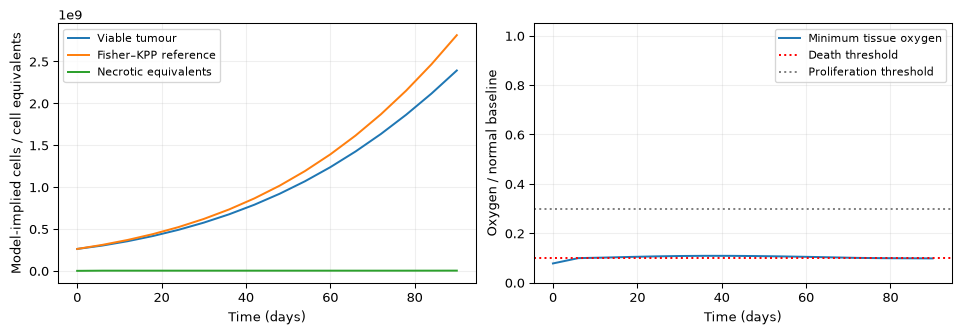

Final viable cells: 2391893641.5764446
Final necrotic equivalents: 2454257.1484375
Final reference cells: 2813309003.8673043


In [5]:
figure = lesson.plot_metrics(result)
figure.savefig(OUTPUT / "trajectories.png", dpi=120)
plt.show()
plt.close(figure)
print("Final viable cells:", result.metrics["cells"][-1])
print("Final necrotic equivalents:", result.metrics["necrotic_cells"][-1])
print("Final reference cells:", result.comparison.metrics["cells"][-1])

## 6. Interactive experiment and slide presets

Use **Load preset**, then press **Run growth simulation**. Model parameters and
seed controls change the next calculation; frame, playback, slices, threshold
and opacity read cached histories. All four panels share the selected day and
physical slice positions. Titles report the nearest sampled coordinates. RAS+
increases rightward, anteriorly and superiorly; the views use neurological
orientation. Model changes are marked pending until the run button is pressed.

| Preset | Grid and duration | Purpose |
|---|---|---|
| CPU teaching | 4 mm, 90 days | Default interactive session |
| Slide comparison | 2 mm, 90 days | Coupled model plus matched Fisher–KPP reference |
| Slide Fisher–KPP | 1 mm, 180 days | Original growth demonstration with its recorded seed and parameters |

The presets record numerical settings from the companion used for the slides.
This notebook uses its exact bundled numerical source. Rendering differs from
the original movie layout. Coarse teaching results differ from the slide runs.

**Try these controlled interventions:**

1. Set $\beta=0$. Check recovery of the matched reference and absence of necrosis.
2. Restore $\beta=4$, then set $\alpha=0$. What changes when delivery no longer
   falls with tumour burden?
3. Change only $D_{GM}$ or $\rho$. Compare shape, viable cells and oxygen.
4. Keep a run fixed and change only threshold and slice positions. Which full
   volume metrics remain invariant?
5. Halve the internal step on the same grid. Then change grid spacing separately.
   Which comparison isolates time-stepping sensitivity?

To move the seed, set all three origin coordinates and radii under **Seed &
density**. Its centre must sample grey/white/glial tissue. Invalid parameters
are reported. Automatic substeps report the actual stable step; disabling them
lets you test rejection of an unstable request.

In [6]:
from brainsmodels.growth_coupled_widgets import coupled_explorer
explorer = coupled_explorer(initial_run=(brain, result), output_directory=OUTPUT / "interactive")
display(explorer.widget)

## 7. Save a reproducible result

The default export below saves a poster and JSON record without recomputing.
The JSON includes parameters, actual numerical steps, source version, input
checksums, time points, full-volume metrics and view settings. The widget's
export button can also write a synchronized GIF or MP4; MP4 uses a bundled
FFmpeg executable. Animation rendering takes additional time. Download exports
before a Colab runtime ends.

In [7]:
lesson.export_run(brain, result, OUTPUT / "reference", planes="All three")
print("Reference files:", sorted(p.name for p in (OUTPUT / "reference").iterdir()))
# Optional: export the current interactive result without rerunning the solver.
# b, r = explorer.last_result
# lesson.export_run(b, r, OUTPUT / "movie", planes="Axial", animation="mp4")
# In Colab, download a ZIP after making your exports:
# import shutil
# from google.colab import files
# files.download(shutil.make_archive(str(OUTPUT), "zip", OUTPUT))

Reference files: ['comparison.png', 'run.json']


## Paired exercises and shared interpretation

**Biomedical and imaging exercise.** Explain why a viable-cell deficit relative to Fisher–KPP can exceed the necrotic count. Predict what removing oxygen uptake should do to the four panels.

**Computational exercise.** Derive the integrated balance, then prove conservation when births and clearance vanish. State every assumption needed for the zero-uptake Fisher–KPP limit.

**Shared interpretation.** The deficit combines reduced births and death transfer; clearance can also remove necrotic material. These are consequences of the stipulated equations, not measurements of a patient's compartments.

## 8. Interpret the model against the biological picture

Return to the illustration. The oxygen–necrosis feedback provides a reduced
mechanism for loss of viable cells in oxygen-poor regions. It supplies no direct
evidence for immune interactions, vessel remodelling, collective migration or
pseudopalisading organisation. Oxygen and density measurements, parameter
estimation and withheld biological outcomes would test additional claims.

### Exercises

1. Two runs have similar threshold volumes but different viable-cell counts.
   How could this occur?
2. With births and necrotic clearance set to zero, what total should be conserved?
3. Why is this coupled run's difference from Fisher–KPP not automatically an improvement?
4. Choose one omitted feature from the illustration. Propose one new variable,
   its coupling and a measurement that could test it.

<details><summary><strong>Show reasoning</strong></summary>

1. Thresholding counts selected voxels equally; integrating density weights
   every voxel, including low-density infiltration hidden by the display.
2. On a no-flux domain, the integral of $c+z$ should remain constant. Death
   transfers material between the two compartments. Clearance would remove it.
3. Additional assumptions produce different predictions; independent observations
   are needed to decide whether those assumptions improve the intended use.
4. For example, a vessel-density state could modify oxygen delivery and respond
   to a hypoxia signal. A measured vascular quantity and oxygen data would be
   needed; adding a variable alone supplies no validation.

</details>

**Takeaway:** richer biology increases the questions a model can express and the
evidence needed to assess its answers.

## Sources and reproduction

- [Pinned numerical source and licence](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/_vendor/brainweb_kpp/PROVENANCE.md).
- [Bundled illustration and preset provenance](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/data/growth/README.md).
- [BrainWeb input checksums, terms and attribution](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/data/brainweb/README.md).
- Comba et al. (2021), [original Figure 1 and article](https://doi.org/10.3389/fonc.2021.703764).

For independent checks of the coupled solver, views, exports and real widget
callbacks, run `make check-growth-coupled`. For the local notebook and Colab
bootstrap checks, see the repository's notebook guide.